In [1]:
#| label: import
library(ggplot2)
library(randomForest)
library(reshape2)

randomForest 4.7-1.2



Type rfNews() to see new features/changes/bug fixes.




Attaching package: ‘randomForest’




The following object is masked from ‘package:ggplot2’:

    margin




## Solution 1: PDP and ICE in case of interactions

In [2]:
#| label: ice-pdp
## f: prediction function | X: n*p data frame | j: column name or index | grid: vector of g values
ice = function(f, X, j, grid) {
  j = if (is.numeric(j)) names(X)[j] else j        # allow numeric or name
  g = length(grid)
  n = nrow(X)
  X_rep = X[rep(seq_len(n), each = g), ]           # repeat rows
  X_rep[[j]] = rep(grid, times = n)                # grid sweep on column j
  ice_mat = matrix(
    f(X_rep[[1]], X_rep[[2]]),                     # vectorised call
    nrow = n, ncol = g, byrow = TRUE
  )
  colnames(ice_mat) = grid
  ice_mat
}

pdp = function(f, X, j, grid) {
  colMeans(ice(f, X, j, grid))
}

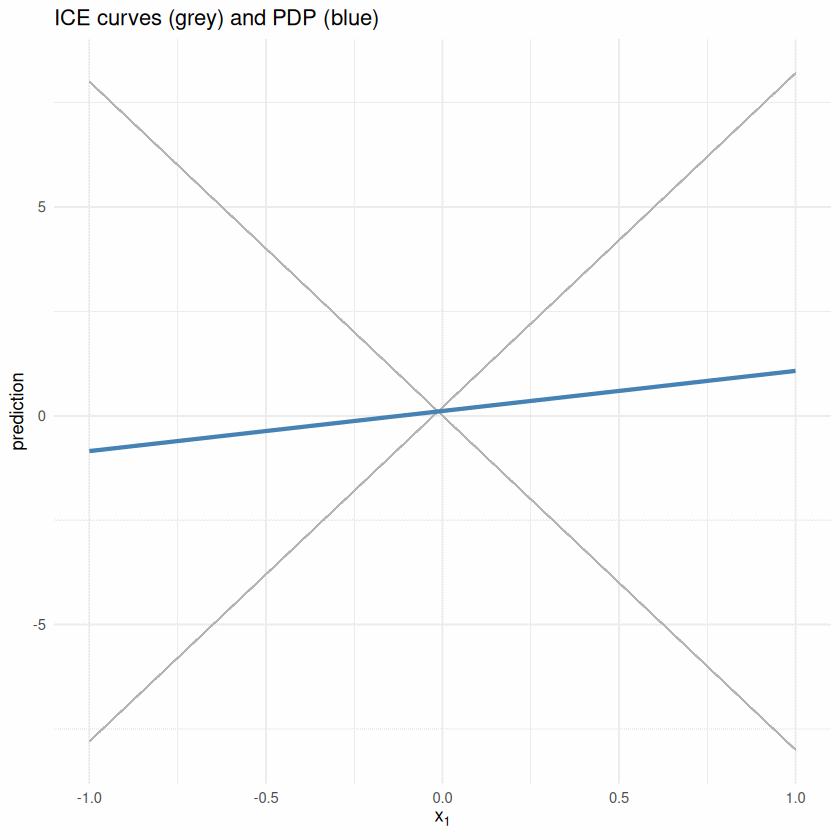

In [3]:
#| label: ice-pdp-example
## linear model with known coefficients (Exercise 1 b)
f_hat = function(x1, x2,
  beta0 = 0, beta1 = -8, beta2 = 0.2, beta3 = 16) {
  beta0 + beta1 * x1 + beta2 * x2 + beta3 * x1 * x2
}

set.seed(42)
n = 100
X = data.frame(
  x1 = runif(n, -1, 1),          # Unif(-1,1)
  x2 = rbinom(n, 1, 0.5)         # Bernoulli(0.5)
)
grid = seq(-1, 1, by = 0.25)     # evaluation grid for x1

ICE = ice(f_hat, X, "x1", grid)
PDP = pdp(f_hat, X, "x1", grid)

## reshape to long format for ggplot2
ice_long = data.frame(
  id   = rep(seq_len(nrow(ICE)), each = ncol(ICE)),
  x1   = rep(grid, times = nrow(ICE)),
  pred = as.vector(t(ICE))
)
pdp_df = data.frame(x1 = grid, pred = PDP)

ggplot() +
  geom_line(data = ice_long,
    aes(x = x1, y = pred, group = id),
    colour = "grey70", linewidth = 0.3) +
  geom_line(data = pdp_df,
    aes(x = x1, y = pred),
    colour = "steelblue", linewidth = 1.2) +
  labs(title = "ICE curves (grey) and PDP (blue)",
    x = expression(x[1]),
    y = "prediction") +
  theme_minimal()

In [4]:
#| label: c-ice-pdp
## ref: index (1 ... g) of the reference grid point
c_ice = function(f, X, j, grid, ref = 1) {
  M = ice(f, X, j, grid)
  sweep(M, 1, M[, ref])         # subtract row-specific reference
}

c_pdp = function(f, X, j, grid, ref = 1) {
  colMeans(c_ice(f, X, j, grid, ref = ref))
}

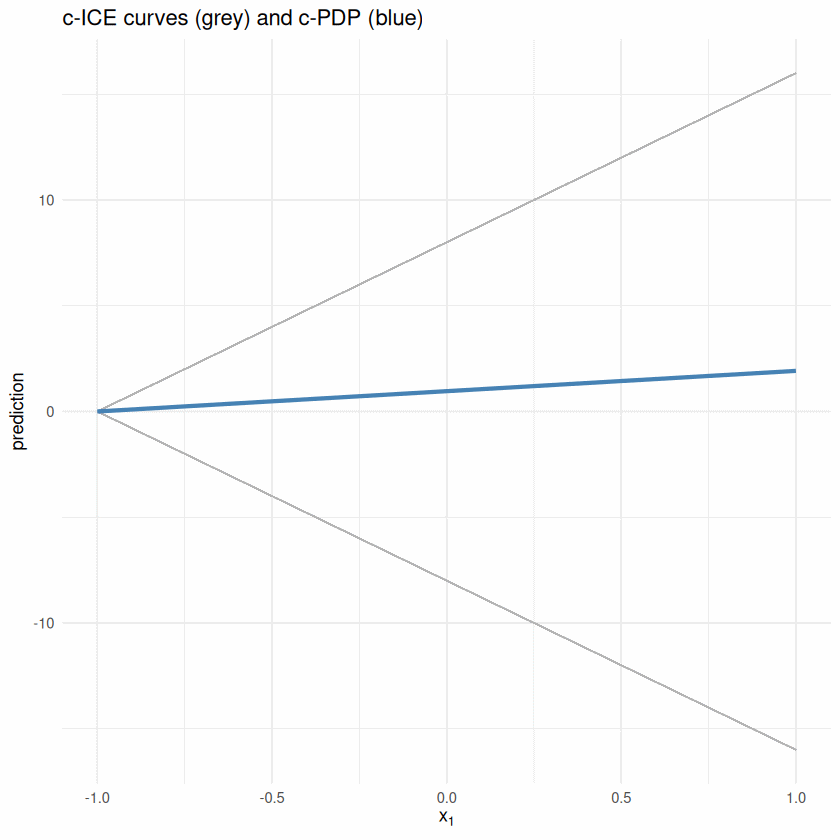

In [5]:
#| label: c-ice-pdp-example
cICE = c_ice(f_hat, X, "x1", grid, ref = which.min(grid))
cPDP = c_pdp(f_hat, X, "x1", grid, ref = which.min(grid))

cice_long = data.frame(
  id   = rep(seq_len(nrow(cICE)), each = ncol(cICE)),
  x1   = rep(grid, times = nrow(cICE)),
  pred = as.vector(t(cICE))
)
cpdp_df = data.frame(x1 = grid, pred = cPDP)

ggplot() +
  geom_line(data = cice_long,
    aes(x = x1, y = pred, group = id),
    colour = "grey70", linewidth = 0.3) +
  geom_line(data = cpdp_df,
    aes(x = x1, y = pred),
    colour = "steelblue", linewidth = 1.2) +
  labs(title = "c-ICE curves (grey) and c-PDP (blue)",
    x = expression(x[1]),
    y = "prediction") +
  theme_minimal()

## Solution 2: Derivative, Forward, and Non-Linearity Effects

In [6]:
#| label: dme-fme-nlm
## numerical derivative marginal effect (central difference)
dME = function(f, x, j, h = 1e-5) {
  x_forward = x
  x_backward = x
  x_forward[j] = x_forward[j] + h
  x_backward[j] = x_backward[j] - h
  (f(x_forward[1], x_forward[2]) - f(x_backward[1], x_backward[2])) / (2 * h)
}

## forward marginal effect with a vector of stepsizes
fME = function(f, x, h_vec) {
  x_perturbed = x + h_vec
  f(x_perturbed[1], x_perturbed[2]) - f(x[1], x[2])
}

## Non-Linearity Measure (R^2 of the secant along the path)
NLM = function(f, x, h_vec, t_vals = seq(0.1, 0.9, length.out = 9)) {
  x_path = sapply(t_vals, function(t) x + t * h_vec)
  f_vals = apply(x_path, 2, function(pt) f(pt[1], pt[2]))
  f_bar = mean(f_vals)
  fme_val = fME(f, x, h_vec)
  g_vals = sapply(t_vals, function(t) f(x[1], x[2]) + t * fme_val)
  1 - sum((f_vals - g_vals)^2) / sum((f_vals - f_bar)^2)
}

In [7]:
#| label: dme-fme-nlm-check
## model of Exercise 2
f_hat = function(x1, x2, theta0 = 0, theta1 = 1, theta2 = 0.5, theta12 = 2) {
  theta0 + theta1 * x1^2 + theta2 * x2^2 + theta12 * x1 * x2
}

x = c(1, 2)

cat("dME_1(1, 2)        =", dME(f_hat, x, j = 1), "\n")
cat("fME_1(1, 2; h = 1)  =", fME(f_hat, x, h_vec = c(1, 0)), "\n")
cat("fME_1(1, 2; h = 0.5)=", fME(f_hat, x, h_vec = c(0.5, 0)), "\n")
cat("NLM (h = 0.5)       =", NLM(f_hat, x, h_vec = c(0.5, 0)), "\n")

dME_1(1, 2)        = 6 


fME_1(1, 2; h = 1)  = 7 


fME_1(1, 2; h = 0.5)= 3.25 


NLM (h = 0.5)       = 0.996714 


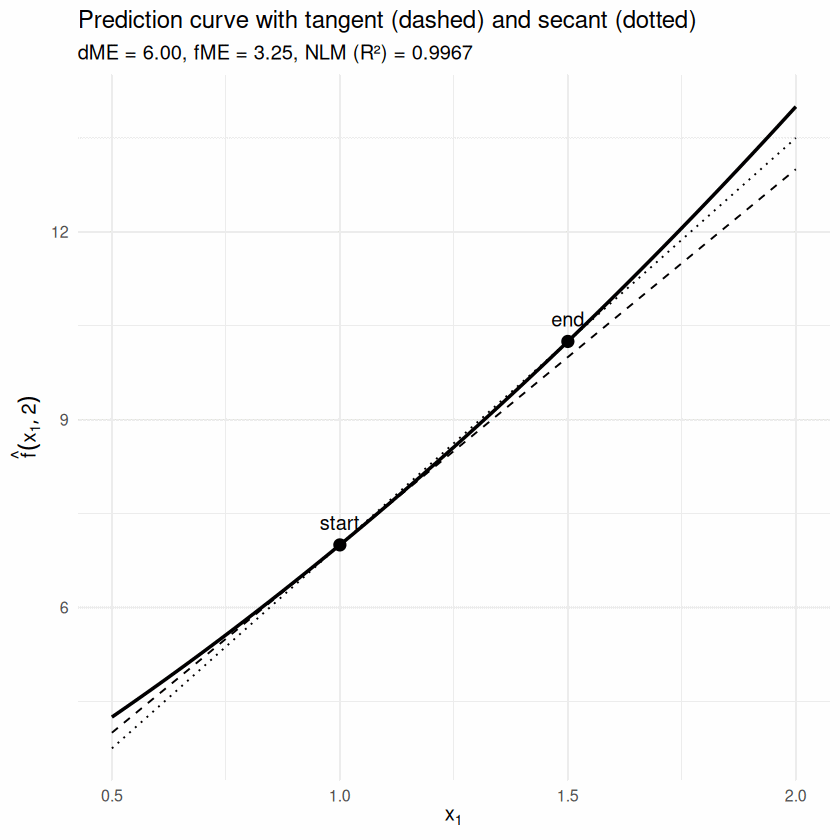

In [8]:
#| label: dme-fme-plot
h_vec = c(0.5, 0)       # step in x1 only
h1 = h_vec[1]
dme_val = dME(f_hat, x, j = 1)
fme_val = fME(f_hat, x, h_vec)
nlm_val = NLM(f_hat, x, h_vec)

## prediction curve in the neighbourhood of x1
x_seq = seq(x[1] - 0.5, x[1] + h1 + 0.5, length.out = 400)
curve_df = data.frame(x = x_seq, y = f_hat(x_seq, x[2]))

## tangent (dashed) and secant (dotted)
tan_df = data.frame(x = x_seq, y = f_hat(x[1], x[2]) + dme_val * (x_seq - x[1]))
sec_df = data.frame(x = x_seq, y = f_hat(x[1], x[2]) + fme_val / h1 * (x_seq - x[1]))

## start / end points of the step
pts_df = data.frame(
  x = c(x[1], x[1] + h1),
  y = c(f_hat(x[1], x[2]), f_hat(x[1] + h1, x[2])),
  lbl = c("start", "end")
)

ggplot(curve_df, aes(x, y)) +
  geom_line(linewidth = 1, colour = "black") +
  geom_line(data = tan_df, linetype = "dashed") +
  geom_line(data = sec_df, linetype = "dotted") +
  geom_point(data = pts_df, size = 3) +
  geom_text(data = pts_df, aes(label = lbl), vjust = -1) +
  labs(title = "Prediction curve with tangent (dashed) and secant (dotted)",
    subtitle = sprintf("dME = %.2f, fME = %.2f, NLM (R\u00b2) = %.4f",
      dme_val, fme_val, nlm_val),
    x = expression(x[1]), y = expression(hat(f)(x[1], 2))) +
  theme_minimal(base_size = 12)

## Solution 3: ALE

In [9]:
#| label: ale-data
## wheat seeds data: predict the (normalized) Type from the numeric features
df = na.omit(read.csv("../data/wheat_seeds.csv"))
df$Type = (df$Type - min(df$Type)) / (max(df$Type) - min(df$Type))
X = df[, setdiff(names(df), "Type")]

## fit a random forest on a 70% training split
set.seed(42)
train = sample(nrow(X), 0.7 * nrow(X))
model = randomForest(x = X[train, ], y = df$Type[train])

Warning message in randomForest.default(x = X[train, ], y = df$Type[train]):
“The response has five or fewer unique values.  Are you sure you want to do regression?”


In [10]:
#| label: get-bounds
get_bounds = function(X, s, n_intervals = 100) {
  ### Luckily for us the seq()-function already implements
  ### exactly what we want if we take two neighboring
  ### equidistant points as the boundaries of one interval.
  ### Now we need n_intervals + 1 points since we always
  ### need two points for one interval resulting
  ### in one point more than the number of intervals we want.
  seq(min(X[, s]), max(X[, s]), length.out = n_intervals + 1)
}

## bounds of 4 intervals for the first feature (Area)
get_bounds(X, s = 1, n_intervals = 4)

[1] 10.5900 13.2375 15.8850 18.5325 21.1800

In [11]:
#| label: calculate-ale
calculate_ale = function(model, X, s, n_intervals = 100, centered = FALSE) {
  ### Get the feature column specified by s from the input data.
  x_s = X[, s]

  ### Save all possible lower and upper bounds in
  ### lowerbounds and upperbounds, respectively.
  boundary_points = get_bounds(X, s, n_intervals)
  lowerbounds = boundary_points[1:n_intervals]
  upperbounds = boundary_points[2:(n_intervals + 1)]

  ### Now we want to iterate over all intervals. For this we
  ### will use mapply() in the following but for readability we define the
  ### function to apply before. This function returns the
  ### uncentered ALE value for one interval given the left and the right
  ### boundary of the interval.
  uncentered_ale_calculation = function(left_boundary, right_boundary) {
    ### The first interval is of the form [left_boundary, right_boundary]
    ### (so that we do not ignore the points with the minimal feature value).
    if (left_boundary == lowerbounds[1]) {
      idxs = which(x_s >= left_boundary & x_s <= right_boundary)
    }
    ### All other intervals are of the form (left_boundary, right_boundary]
    ### (so that no point falls into two intervals).
    else {
      idxs = which(x_s > left_boundary & x_s <= right_boundary)
    }

    ### If there is no point in the interval return 0
    ### (as stated in the task).
    if (length(idxs) == 0) {
      return(0)
    }

    ### Else we compute the ALE value. The first step is to
    ### replace the feature values of all the points that fall into the interval
    ### with the left and the right boundary of the interval.
    X_min = X[idxs, ]
    X_max = X[idxs, ]
    X_min = replace(X_min, s, left_boundary)
    X_max = replace(X_max, s, right_boundary)

    ### Then we let the model predict these "new" data points.
    y_min = predict(model, X_min)
    y_max = predict(model, X_max)

    ### We return the arithmetic mean of the prediction differences.
    mean(y_max - y_min)
  }

  ### Now we can calculate the ALE values all at once with the mapply()-function.
  ### We accumulate them via the cumsum()-function.
  ale_values = cumsum(mapply(uncentered_ale_calculation, lowerbounds, upperbounds))

  ### If the centered argument is set to TRUE the user wants us to center the ALE values.
  if (centered)
    ale_values = ale_values - mean(ale_values)

  ### Return the boundary points as well as the centered or uncentered ALE values.
  list(bounds = boundary_points, ale = ale_values)
}

## uncentered ALE of the first feature with 4 intervals
calculate_ale(model, X, s = 1, n_intervals = 4)

$bounds
[1] 10.5900 13.2375 15.8850 18.5325 21.1800

$ale
[1] 0.1423909 0.2201745 0.2350198 0.2350198

In [12]:
#| label: prepare-ale
prepare_ale = function(model, X, s, n_intervals = 100, centered = TRUE) {
  ### Get the ALE values via our function from task b).
  ale = calculate_ale(model, X, s, n_intervals, centered)

  ### Get the bounds and y from the list.
  bounds = unlist(ale[1])
  y = unlist(ale[2])

  ### Reconstruct the lowerbounds and upperbounds vectors.
  lowerbounds = bounds[1:n_intervals]
  upperbounds = bounds[2:(n_intervals + 1)]

  ### Get the center of each interval.
  x = rowMeans(cbind(lowerbounds, upperbounds))

  ### Now for ggplot2 the expected format is a data.frame.
  data.frame(x = x, y = y)
}

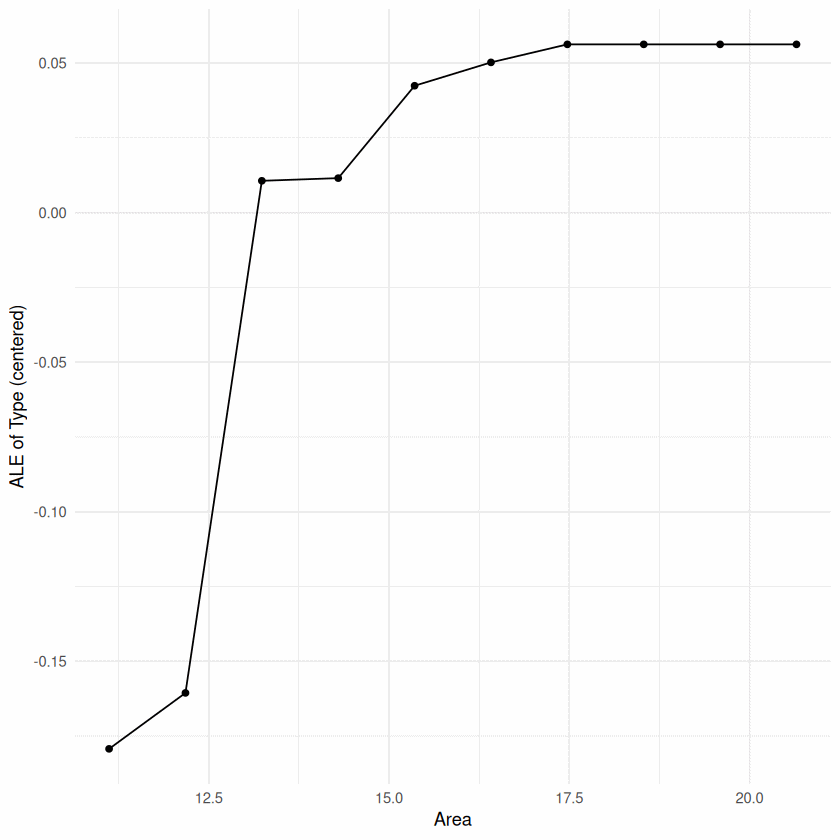

In [13]:
#| label: ale-plot
prepared_ale = prepare_ale(model, X, s = 1, n_intervals = 10, centered = TRUE)

ggplot(data = prepared_ale, mapping = aes(x = x, y = y)) +
  geom_line() +
  geom_point() +
  labs(x = "Area", y = "ALE of Type (centered)") +
  theme_minimal()

## Solution 4: Categorical ALE

In [14]:
#| label: catale-given
credit = read.csv("../data/credit.csv", stringsAsFactors = TRUE)

order_levels = function(data, feature.name) {
  feature = data[, feature.name]
  others = setdiff(colnames(data), feature.name)
  feature.lev = unique(feature)

  ### Iterate over other features
  dists = lapply(others, function(k) {
    feature.k = data[, k]
    if (inherits(feature.k, "factor") | inherits(feature.k, "character")) {
      dists = get_diff_cat(feature.k, feature)
    } else {
      dists = get_diff_numeric(feature.k, feature)
    }
    dists
  })
  dists.cumulated.long = as.data.frame(Reduce(function(d1, d2) {
    d1$dist = d1$dist + d2$dist
    d1
  }, dists))

  ### Create a matrix of distances
  dists.cumulated = reshape2::dcast(dists.cumulated.long,
    class1 ~ class2, value.var = "dist")[, -1]
  rownames(dists.cumulated) = colnames(dists.cumulated)

  ### conduct multi-dimensional scaling (here: principal coordinates analysis)
  ### based on dissimilarity matrix it assigns
  ### to each item a location in a low dimensional space
  ### the closer the location, the more similar the items are.
  scaled = cmdscale(dists.cumulated, k = 1)
  feature.lev[order(scaled)]
}

get_diff_numeric = function(feature.k, feature.j) {
  ### set up data.frame which we will fill later
  dists = expand.grid(unique(feature.j), unique(feature.j))
  colnames(dists) = c("class1", "class2")

  ### get decentiles
  quants = quantile(feature.k, probs = seq(0, 1, length.out = 10),
    na.rm = TRUE, names = FALSE)

  ### derive empirical distribution function for each category
  ecdfs = data.frame(lapply(unique(feature.j), function(lev) {
    x.ecdf = ecdf(feature.k[feature.j == lev])(quants)
    return(x.ecdf)
  }))
  colnames(ecdfs) = unique(feature.j)

  ### get pairwise absolute distances of empirical distribution function
  ### between the different categories
  ecdf.dists.all = abs(ecdfs[, dists$class1] - ecdfs[, dists$class2])

  ### get maximum distance over decentiles for each pair of categories
  dists$dist = apply(ecdf.dists.all, 2, max)
  dists
}

In [15]:
#| label: get-diff-cat
get_diff_cat = function(feature.k, feature.j) {
  ### set up data.frame which we will fill later
  dists = expand.grid(unique(feature.j), unique(feature.j))
  colnames(dists) = c("class1", "class2")

  ### get relative frequency table
  x.count = as.numeric(table(feature.j))
  A = table(feature.j, feature.k) / x.count

  ### compute pairwise absolute distances
  dists$dist = rowSums(
    abs(A[as.character(dists[, "class1"]), ] - A[as.character(dists[, "class2"]), ]))
  dists
}

In [16]:
#| label: get-diff-cat-example
get_diff_cat(feature.k = credit[, "employment_duration"],
  feature.j = credit[, "personal_status_sex"])

class1,class2,dist
<fct>,<fct>,<dbl>
male : married/widowed,male : married/widowed,0.0000000
female : non-single or male : single,male : married/widowed,0.4482929
male : divorced/separated,male : married/widowed,0.3747445
female : single,male : married/widowed,0.4976198
male : married/widowed,female : non-single or male : single,0.4482929
female : non-single or male : single,female : non-single or male : single,0.0000000
male : divorced/separated,female : non-single or male : single,0.2864516
female : single,female : non-single or male : single,0.1586255
male : married/widowed,male : divorced/separated,0.3747445


In [17]:
#| label: order-levels-example
order_levels(credit, "personal_status_sex")

[1] female : single                      female : non-single or male : single
[3] male : married/widowed               male : divorced/separated           
4 Levels: female : non-single or male : single ... male : married/widowed